# Subjectivity Mining — Assignment 5
## Group 9 — Ines: common setup + hard majority voting

This block reuses the three transformer predictions from Assignment 4:
**BERT, HateBERT and fBERT**.

For hard majority voting, each model casts one binary vote and the class predicted by
at least two of the three models becomes the ensemble prediction.

The same OLID test set and the same in-domain / cross-domain definitions from Assignment 4
are retained.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

DATA = Path("a4_component_predictions.csv")
df = pd.read_csv(DATA)

assert len(df) == 860
assert df["labels"].isin([0,1]).all()
display(df.head())

,id,text,labels,bert_in,hatebert_in,fbert_in,bert_cross,hatebert_cross,fbert_cross,hard_in,hard_cross
0,15923,#WhoIsQ #WheresTheServer #DumpNike #DECLASFISA...,1,1,1,1,1,1,1,1,1
1,27014,"#ConstitutionDay is revered by Conservatives, ...",0,0,0,0,1,0,0,0,0
2,30530,#FOXNews #NRA #MAGA #POTUS #TRUMP #2ndAmendmen...,0,0,0,0,0,0,0,0,0
3,13876,#Watching #Boomer getting the news that she is...,0,0,0,0,0,0,0,0,0
4,60133,#NoPasaran: Unity demo to oppose the far-right...,1,0,0,0,0,0,0,0,0


## 1. Common evaluation function

In [2]:
def evaluate_predictions(y_true, y_pred, model_name, setting, show_matrix=True):
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    p, r, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0,1], zero_division=0
    )

    summary = pd.DataFrame([{
        "model": model_name,
        "setting": setting,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "precision_0": p[0], "recall_0": r[0], "f1_0": f1[0], "support_0": support[0],
        "precision_1": p[1], "recall_1": r[1], "f1_1": f1[1], "support_1": support[1],
    }])

    if show_matrix:
        cm = confusion_matrix(y_true, y_pred, labels=[0,1])
        disp = ConfusionMatrixDisplay(
            cm, display_labels=["Non-offensive (0)", "Offensive (1)"]
        )
        disp.plot(values_format="d")
        plt.title(f"{model_name} — {setting}")
        plt.tight_layout()
        plt.show()

    return summary

## 2. Verify the Assignment 4 component predictions

In [3]:
component_cols = [
    "bert_in", "hatebert_in", "fbert_in",
    "bert_cross", "hatebert_cross", "fbert_cross",
]
assert df[component_cols].isin([0,1]).all().all()

print("Rows:", len(df))
print("All three models agree, in-domain:",
      ((df.bert_in == df.hatebert_in) & (df.hatebert_in == df.fbert_in)).sum())
print("All three models agree, cross-domain:",
      ((df.bert_cross == df.hatebert_cross) & (df.hatebert_cross == df.fbert_cross)).sum())

Rows: 860
All three models agree, in-domain: 707
All three models agree, cross-domain: 647


## 3. Hard majority voting

In [4]:
df["hard_in"] = (
    df[["bert_in", "hatebert_in", "fbert_in"]].sum(axis=1) >= 2
).astype(int)

df["hard_cross"] = (
    df[["bert_cross", "hatebert_cross", "fbert_cross"]].sum(axis=1) >= 2
).astype(int)

assert df["hard_in"].isin([0,1]).all()
assert df["hard_cross"].isin([0,1]).all()

display(df[[
    "id", "labels",
    "bert_in", "hatebert_in", "fbert_in", "hard_in",
    "bert_cross", "hatebert_cross", "fbert_cross", "hard_cross"
]].head(10))

,id,labels,bert_in,hatebert_in,fbert_in,hard_in,bert_cross,hatebert_cross,fbert_cross,hard_cross
0,15923,1,1,1,1,1,1,1,1,1
1,27014,0,0,0,0,0,1,0,0,0
2,30530,0,0,0,0,0,0,0,0,0
3,13876,0,0,0,0,0,0,0,0,0
4,60133,1,0,0,0,0,0,0,0,0
5,83681,1,1,1,1,1,1,1,1,1
6,96874,0,0,0,1,0,0,0,0,0
7,65507,1,0,0,1,0,1,1,1,1
8,78910,0,0,0,0,0,0,0,0,0
9,46363,0,0,0,0,0,0,0,0,0


## 4. In-domain results

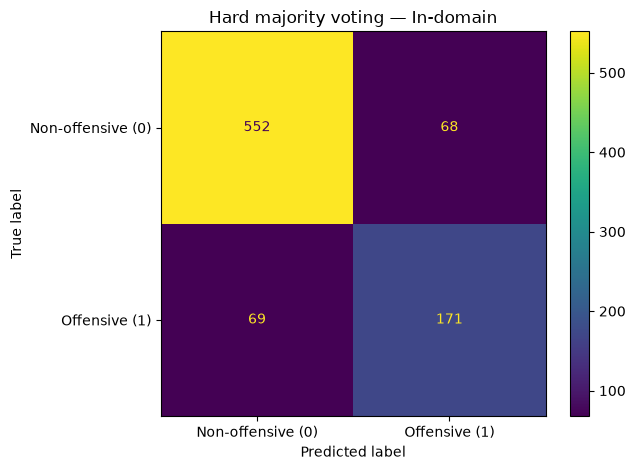

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Hard majority voting,In-domain,0.8407,0.8022,0.8014,0.8018,0.8889,0.8903,0.8896,620,0.7155,0.7125,0.714,240


In [5]:
metrics_in = evaluate_predictions(
    df.labels, df.hard_in,
    "Hard majority voting", "In-domain", show_matrix=True
)
display(metrics_in.round(4))

## 5. Cross-domain results

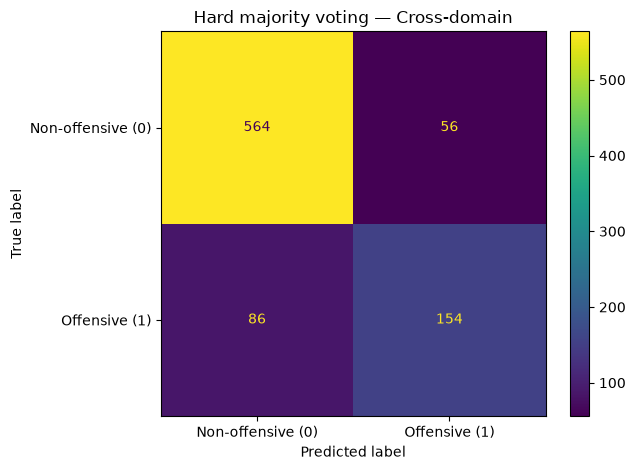

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Hard majority voting,Cross-domain,0.8349,0.8005,0.7757,0.7863,0.8677,0.9097,0.8882,620,0.7333,0.6417,0.6844,240


In [6]:
metrics_cross = evaluate_predictions(
    df.labels, df.hard_cross,
    "Hard majority voting", "Cross-domain", show_matrix=True
)
display(metrics_cross.round(4))

## 6. Direct comparison and cross-domain drop

In [7]:
comparison = pd.concat([metrics_in, metrics_cross], ignore_index=True)
display(comparison.round(4))

f_in = float(metrics_in.loc[0, "macro_f1"])
f_cross = float(metrics_cross.loc[0, "macro_f1"])
drop = f_in - f_cross

print(f"In-domain macro-F1:     {f_in:.4f}")
print(f"Cross-domain macro-F1:  {f_cross:.4f}")
print(f"Absolute drop:          {drop:.4f}")
print(f"Relative drop:          {100*drop/f_in:.2f}%")

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Hard majority voting,In-domain,0.8407,0.8022,0.8014,0.8018,0.8889,0.8903,0.8896,620,0.7155,0.7125,0.7140,240
1,Hard majority voting,Cross-domain,0.8349,0.8005,0.7757,0.7863,0.8677,0.9097,0.8882,620,0.7333,0.6417,0.6844,240


In-domain macro-F1:     0.8018
Cross-domain macro-F1:  0.7863
Absolute drop:          0.0155
Relative drop:          1.93%


## 7. Comparison with the strongest individual model from Assignment 4

In [8]:
# fBERT was the best individual model in Assignment 4.
fbert_macro_f1_in = 0.8033
fbert_macro_f1_cross = 0.8088

hard_in_f1 = float(metrics_in.loc[0, "macro_f1"])
hard_cross_f1 = float(metrics_cross.loc[0, "macro_f1"])

comparison_best = pd.DataFrame([
    {
        "setting": "In-domain",
        "fBERT_macro_f1": fbert_macro_f1_in,
        "hard_voting_macro_f1": hard_in_f1,
        "difference_hard_minus_fBERT": hard_in_f1 - fbert_macro_f1_in,
    },
    {
        "setting": "Cross-domain",
        "fBERT_macro_f1": fbert_macro_f1_cross,
        "hard_voting_macro_f1": hard_cross_f1,
        "difference_hard_minus_fBERT": hard_cross_f1 - fbert_macro_f1_cross,
    }
])
display(comparison_best.round(4))

,setting,fBERT_macro_f1,hard_voting_macro_f1,difference_hard_minus_fBERT
0,In-domain,0.8033,0.8018,-0.0015
1,Cross-domain,0.8088,0.7863,-0.0225


## 8. Interpretation

Hard majority voting is stable across domains, but it does **not** outperform the strongest
individual model, fBERT. Its in-domain macro-F1 is about 0.802 and its cross-domain macro-F1
is about 0.786. The ensemble therefore loses roughly 1.5 macro-F1 points across domains.

The three transformers agree on most test examples (707/860 in-domain and 647/860
cross-domain). This limits the potential benefit of majority voting: when the models make
similar predictions, voting cannot correct many errors. In the cross-domain setting the
ensemble still improves over BERT and HateBERT individually, but fBERT remains stronger.

## 9. Save files for the final group integration

In [9]:
out = Path(".")

res_in = df[["id","text","labels","bert_in","hatebert_in","fbert_in","hard_in"]].copy()
res_in = res_in.rename(columns={"hard_in":"prediction"})
res_in["correct"] = res_in.labels == res_in.prediction
res_in.to_csv(out / "results_hard_voting_in_domain.csv", index=False)

res_cross = df[["id","text","labels","bert_cross","hatebert_cross","fbert_cross","hard_cross"]].copy()
res_cross = res_cross.rename(columns={"hard_cross":"prediction"})
res_cross["correct"] = res_cross.labels == res_cross.prediction
res_cross.to_csv(out / "results_hard_voting_cross_domain.csv", index=False)

metrics_in.to_csv(out / "metrics_hard_voting_in_domain.csv", index=False)
metrics_cross.to_csv(out / "metrics_hard_voting_cross_domain.csv", index=False)
comparison.to_csv(out / "metrics_hard_voting_comparison.csv", index=False)

print("Saved all hard-voting result and metric files.")

Saved all hard-voting result and metric files.
